# 02 - Temporal Validation

**Objective:** define the train / validation / test splits and verify that each segment is reasonable (size, fraud rate, proportion with identity information).

A random `train_test_split` is not used: in production the model predicts on the future, so we evaluate it the same way.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.validation import add_day, temporal_split, summarize_splits, TRAIN_END_DAY, VALID_END_DAY

sns.set_theme(style="whitegrid")
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
df.shape

(590540, 436)

## 1. Fraud rate by week and proposed splits
The red lines are the splits. It's best that no spike is split right at a cutoff.

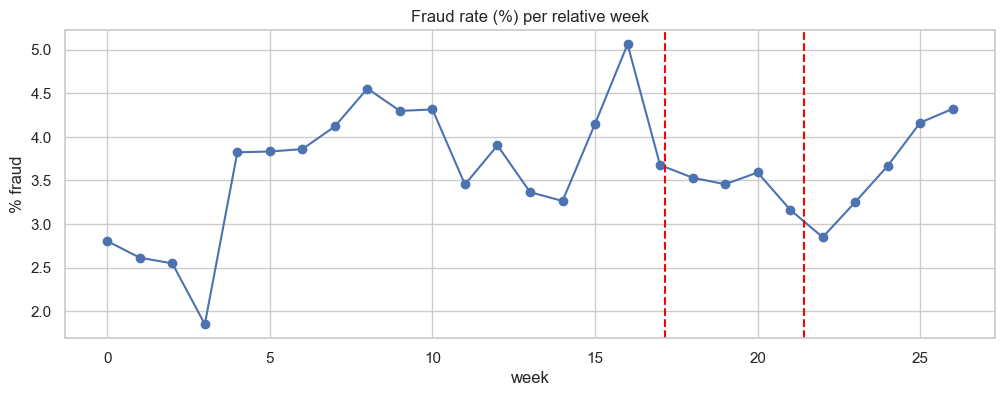

In [2]:
df["week"] = df["day"] // 7
weekly = df.groupby("week")["isFraud"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
weekly.plot(ax=ax, marker="o")
for cut in (TRAIN_END_DAY, VALID_END_DAY):
    ax.axvline(cut / 7, color="red", linestyle="--")
ax.set_title("Fraud rate (%) per relative week")
ax.set_xlabel("week"); ax.set_ylabel("% fraud")
plt.show()

## 2. Split and summary by segment

In [3]:
train, valid, test = temporal_split(df)
summarize_splits(train=train, valid=valid, test=test)

,rows,% of total,day_min,day_max,frauds,fraud_rate_%,%_with_identity
split,,,,,,,
train,410601,69.53,1,119,14419,3.51,26.64
valid,85303,14.44,120,149,2962,3.47,17.72
test,94636,16.03,150,182,3282,3.47,20.86


## 3. Stability of `has_identity` and `ProductCD` across segments
If the composition changes a lot between train and test, the model may degrade due to *drift*.

In [4]:
pd.concat({
    name: part["ProductCD"].value_counts(normalize=True).round(3)
    for name, part in {"train": train, "valid": valid, "test": test}.items()
}, axis=1)

,train,valid,test
ProductCD,,,
W,0.720,0.816,0.786
C,0.121,0.104,0.105
R,0.073,0.038,0.047
H,0.068,0.027,0.029
S,0.017,0.016,0.033


In [5]:
pd.concat({
    name: part.groupby("has_identity")["isFraud"].mean().round(4)
    for name, part in {"train": train, "valid": valid, "test": test}.items()
}, axis=1)

,train,valid,test
has_identity,,,
0,0.0214,0.0213,0.0187
1,0.0729,0.0970,0.0951


## 4. Decisions and observations

**Chosen splits**
- Train: days 1-119 (69.5%) | Validation: 120-149 (14.4%) | Test: 150-182 (16.0%).
- No `gap_days` (= 0) for now. This can be revisited if leakage is suspected from cards appearing on both sides of a split.
- The week 16 fraud spike (~5.0%) falls entirely within train. The day 120 cutoff lands in a calm zone (week 17, ~3.5%), so no spike is split.

**Split verification**
- The fraud rate is stable: 3.51% / 3.47% / 3.47%.
- There are enough fraud cases to evaluate reliably: 2,962 in validation and 3,282 in test.

**Observed drift**
- `ProductCD`: the composition changes. W goes from 72% in train to 82% in validation and 79% in test, while H (6.8% → 2.7%) and R (7.3% → 3.8%) drop by half or more.
- `has_identity`: coverage drops from 26.6% in train to 17.7% in validation and 20.9% in test. Additionally, the fraud rate of the identity group rises from 7.3% (train) to ~9.6% (valid/test), while that of the no-identity group stays at ~2%.
- Both changes offset each other at the global level (which is why the overall rate doesn't move), but the model will see a different population mix than the one it was trained on.

**Implications for modeling**
- Also evaluate metrics by segment (`ProductCD`, `has_identity`), not just overall.
- Be careful with variables that depend on population composition: they may degrade out of time.
- Always report results on temporal validation and test sets, never with random splits.